# 03 — Modelos clásicos: características, línea base, SVM y Random Forest

**Fases CRISP-DM:** preparación de los datos (recortes y características) y modelado.

Los modelos se entrenan con `python -m src.training.entrenar clasicos` (unos 30 minutos en CPU); este notebook carga lo que ese script guardó en `experiments/results/` y `experiments/checkpoints/`, y hace los análisis que no son costosos. La formulación está en `docs/formulacion_matematica.md` (secciones 4 y 5).

In [1]:
import sys, json, os
from pathlib import Path

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ))
os.environ["PYTHONPATH"] = str(RAIZ)  # para los procesos de joblib

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from joblib import parallel_backend
from sklearn.model_selection import StratifiedKFold, cross_val_score, learning_curve

from src.config import RECORTES, RESULTADOS, CHECKPOINTS, CLASES_ENTRENAMIENTO, FRUTAS_PROYECTO, SEMILLA
from src.data.recortes import cargar_conjunto
from src.features.extraccion import columnas_por_grupo
from src.models.clasicos import crear_modelo, NOMBRES
from src.training.entrenar import cargar_caracteristicas, matriz
from src.utils.visualizacion import estilo, guardar_figura, leer_rgb

estilo()
CLASES = CLASES_ENTRENAMIENTO
df, columnas = cargar_caracteristicas()
dev = df[df["particion"] != "test"].reset_index(drop=True)
print(f"{len(df)} imágenes con segmentación válida, {len(columnas)} características")
pd.crosstab([df["fruta"], df["calidad"]], df["particion"], margins=True)

6495 imágenes con segmentación válida, 78 características


particion        test  train  val   All
fruta   calidad                        
banano  buena     133    666  137   936
        mala      149    727  151  1027
manzana buena     158    731  157  1046
        mala      171    788  167  1126
naranja buena     182    845  181  1208
        mala      173    806  173  1152
All               966   4563  966  6495

## 1. Recortes segmentados

Cada imagen se segmenta con GrabCut, se recorta a un cuadrado alrededor de la fruta y se pinta el fondo de negro (`src/data/recortes.py`). Así los modelos solo ven la fruta y todas las imágenes tienen la misma resolución.

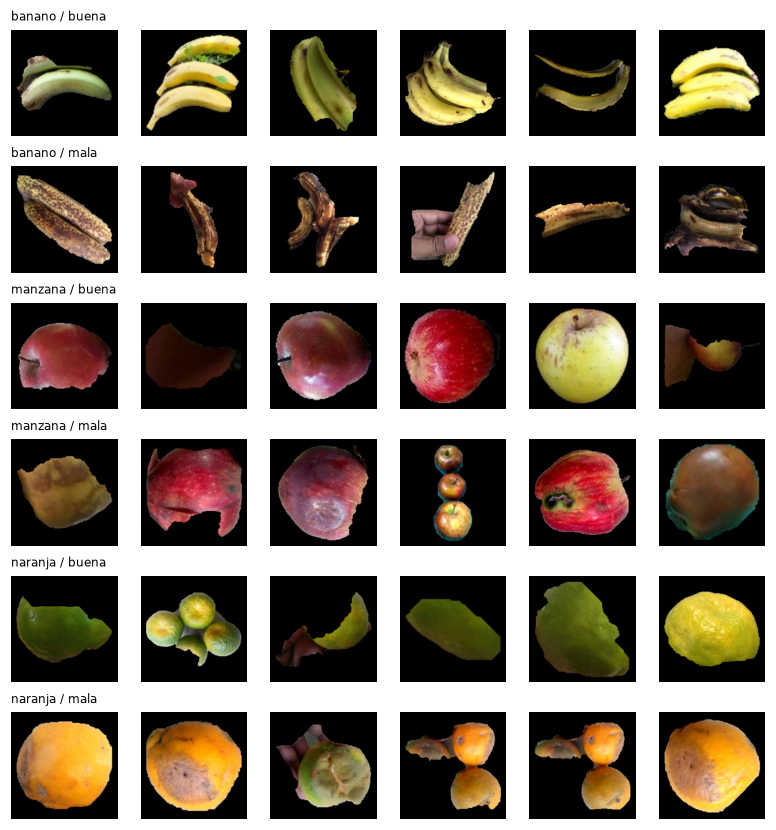

In [2]:
conj = cargar_conjunto()
ej = conj.groupby(["fruta", "calidad"]).sample(6, random_state=SEMILLA)
fig, axes = plt.subplots(6, 6, figsize=(7.2, 7.6))
for ax, (_, r) in zip(axes.ravel(), ej.iterrows()):
    ax.imshow(leer_rgb(RECORTES / r["recorte"])); ax.axis("off")
for i, ((f, c), _) in enumerate(ej.groupby(["fruta", "calidad"], sort=False)):
    axes[i, 0].set_title(f"{f} / {c}", fontsize=8, loc="left")
fig.tight_layout()
guardar_figura(fig, "prep_recortes_ejemplos", raster=True)
plt.show()

## 2. Características por clase

Distribución de algunas características por fruta y clase. Sirve para ver si la relación con la calidad es la misma en las tres frutas.

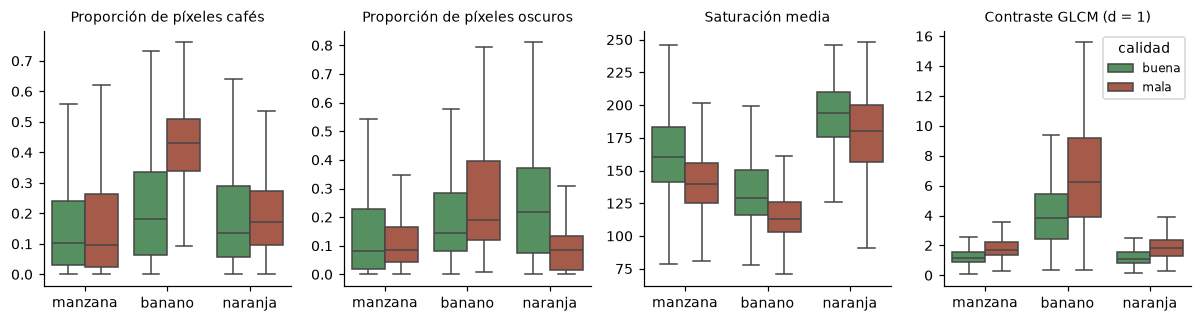

def_cafe  def_oscuro  mom_hsv_s_media  glcm_contrast_d1
fruta   calidad                                                         
banano  buena       0.181       0.144          129.404             3.829
        mala        0.431       0.189          113.129             6.236
manzana buena       0.104       0.081          160.143             1.150
        mala        0.096       0.087          140.026             1.673
naranja buena       0.134       0.217          193.935             1.096
        mala        0.173       0.085          180.000             1.847

In [3]:
sel = {"def_cafe": "Proporción de píxeles cafés", "def_oscuro": "Proporción de píxeles oscuros",
       "mom_hsv_s_media": "Saturación media", "glcm_contrast_d1": "Contraste GLCM (d = 1)"}
fig, axes = plt.subplots(1, 4, figsize=(11, 3))
for ax, (col, titulo) in zip(axes, sel.items()):
    sns.boxplot(data=df, x="fruta", y=col, hue="calidad", hue_order=CLASES, ax=ax,
                showfliers=False, palette={"buena": "#4c9a5a", "mala": "#b5523b", "regular": "#d9a441"})
    ax.set_title(titulo, fontsize=9); ax.set_xlabel(""); ax.set_ylabel("")
    if ax is not axes[-1]:
        ax.get_legend().remove()
fig.tight_layout()
guardar_figura(fig, "feat_distribuciones")
plt.show()
df.groupby(["fruta", "calidad"])[list(sel)].median().round(3)

## 3. ¿Qué tanto predicen la calidad las condiciones de captura?

Antes de mirar los modelos de calidad se mide el atajo encontrado en el EDA: con variables de la **imagen completa** que no describen la fruta (brillo, saturación, contraste, nitidez, brillo del fondo y resolución) se entrena un clasificador de calidad (`python -m src.training.entrenar sesgo`). Si ese clasificador funciona bien, un buen resultado en la prueba interna no basta para decir que el modelo mira la fruta.

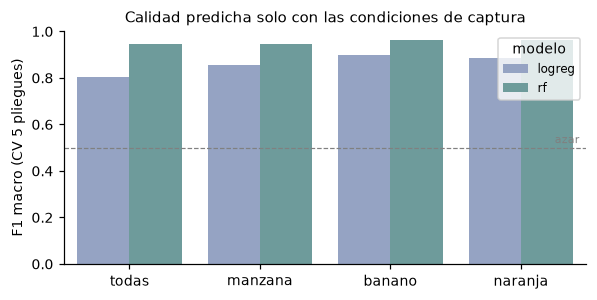

,fruta,modelo,cv_f1,cv_f1_std
0,todas,logreg,0.8062,0.0098
1,todas,rf,0.9466,0.0039
2,manzana,logreg,0.8544,0.0126
3,manzana,rf,0.9461,0.0084
4,banano,logreg,0.8982,0.0226
5,banano,rf,0.9636,0.0069
6,naranja,logreg,0.8877,0.0121
7,naranja,rf,0.9626,0.0039


In [4]:
sesgo = pd.read_csv(RESULTADOS / "sesgo_captura.csv")
fig, ax = plt.subplots(figsize=(5.5, 2.8))
sns.barplot(data=sesgo, x="fruta", y="cv_f1", hue="modelo", ax=ax, palette=["#8da0cb", "#66a3a3"])
ax.axhline(0.5, ls="--", c="gray", lw=0.8)
ax.text(3.45, 0.52, "azar", fontsize=7, color="gray", ha="right")
ax.set_ylim(0, 1); ax.set_ylabel("F1 macro (CV 5 pliegues)"); ax.set_xlabel("")
ax.set_title("Calidad predicha solo con las condiciones de captura", fontsize=10)
fig.tight_layout()
guardar_figura(fig, "sesgo_captura")
plt.show()
sesgo

**Lectura.** Con siete números que describen la foto y no la fruta, un Random Forest predice la calidad con F1 ≈ 0,95 en las tres frutas; la regresión logística llega a 0,81–0,90. El dataset se puede resolver por un atajo (*shortcut learning*): las fotos *bad* se tomaron con otro fondo, otra luz y otra cámara.

Los modelos de este notebook trabajan solo con la fruta segmentada, pero eso no elimina el atajo del todo: la luz de la foto cambia el color medido de la fruta, la nitidez cambia la textura y en algunas *bad* queda parte de la mano dentro de la máscara. Por eso los resultados de la prueba interna son una **cota optimista**, y la prueba que decide es la de las fotos propias.

## 4. Búsqueda de hiperparámetros

Tres modelos (regresión logística como línea base, SVM con kernel RBF y Random Forest), cada uno con `GridSearchCV`, validación cruzada estratificada de 5 pliegues y F1 macro como métrica. Se prueban tres configuraciones:

- **global**: un modelo para las tres frutas, sin decirle cuál es;
- **global_fruta**: un modelo con la fruta como variable (codificación *one-hot*);
- **por_fruta**: un modelo independiente para cada fruta.

In [5]:
cv = pd.read_csv(RESULTADOS / "clasicos_cv_resumen.csv")
cv["brecha"] = cv["train_f1"] - cv["cv_f1"]
cv

,configuracion,modelo,fruta,mejores_parametros,cv_f1,cv_f1_std,train_f1,brecha
0,global,logreg,todas,"{""C"": 100}",0.9108,0.0063,0.9162,0.0054
1,global,svm,todas,"{""C"": 10, ""gamma"": ""scale""}",0.9815,0.0059,0.9981,0.0166
2,global,rf,todas,"{""max_depth"": null, ""max_features"": ""sqrt"", ""m...",0.9664,0.0033,1.0000,0.0336
3,global_fruta,logreg,todas,"{""C"": 10}",0.9131,0.0063,0.9178,0.0047
4,global_fruta,svm,todas,"{""C"": 10, ""gamma"": ""scale""}",0.9824,0.0067,0.9982,0.0158
5,global_fruta,rf,todas,"{""max_depth"": null, ""max_features"": ""sqrt"", ""m...",0.9680,0.0035,1.0000,0.0320
6,por_fruta,logreg,manzana,"{""C"": 10}",0.9277,0.0095,0.9488,0.0211
7,por_fruta,logreg,banano,"{""C"": 1}",0.9899,0.0040,0.9979,0.0080
8,por_fruta,logreg,naranja,"{""C"": 1}",0.9496,0.0076,0.9621,0.0125
9,por_fruta,svm,manzana,"{""C"": 10, ""gamma"": ""scale""}",0.9777,0.0074,0.9999,0.0222


In [6]:
# Para por_fruta se promedia el F1 de CV de las tres frutas, ponderado por el número de imágenes
n_fruta = dev["fruta"].value_counts()
def resumen_config(g):
    w = g["fruta"].map(n_fruta).fillna(len(dev)) if (g["fruta"] != "todas").any() else pd.Series(1, index=g.index)
    return pd.Series({"cv_f1": np.average(g["cv_f1"], weights=w), "train_f1": np.average(g["train_f1"], weights=w)})
cv_cfg = cv.groupby(["configuracion", "modelo"]).apply(resumen_config, include_groups=False).reset_index()
test = pd.read_csv(RESULTADOS / "clasicos_test.csv")
comp = cv_cfg.merge(test[["configuracion", "modelo", "f1_macro", "f1_macro_ic_inf", "f1_macro_ic_sup", "recall_mala", "auc"]],
                    on=["configuracion", "modelo"])
comp.round(4)

,configuracion,modelo,cv_f1,train_f1,f1_macro,f1_macro_ic_inf,f1_macro_ic_sup,recall_mala,auc
0,global,logreg,0.9108,0.9162,0.9015,0.8799,0.9200,0.9189,0.9642
1,global,rf,0.9664,1.0000,0.9700,0.9585,0.9793,0.9716,0.9910
2,global,svm,0.9815,0.9981,0.9834,0.9741,0.9907,0.9878,0.9972
3,global_fruta,logreg,0.9131,0.9178,0.9005,0.8799,0.9191,0.9168,0.9652
4,global_fruta,rf,0.9680,1.0000,0.9700,0.9585,0.9793,0.9696,0.9914
5,global_fruta,svm,0.9824,0.9982,0.9855,0.9772,0.9917,0.9878,0.9976
6,por_fruta,logreg,0.9546,0.9686,0.9617,0.9491,0.9731,0.9655,0.9900
7,por_fruta,rf,0.9737,0.9998,0.9710,0.9596,0.9813,0.9696,0.9954
8,por_fruta,svm,0.9842,0.9998,0.9845,0.9762,0.9917,0.9817,0.9985


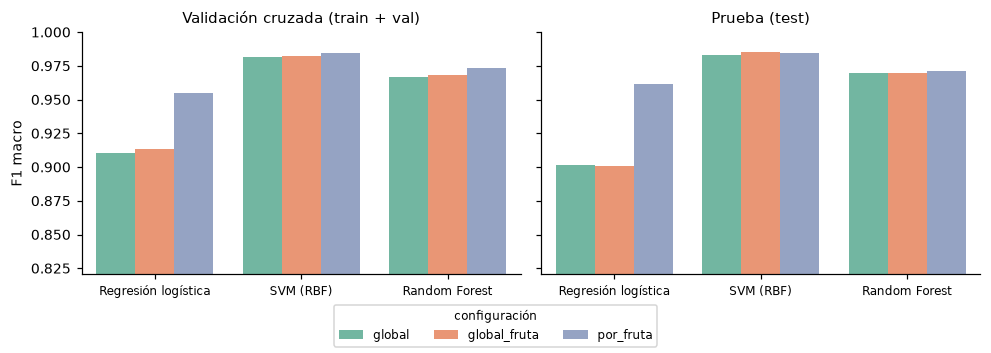

In [7]:
orden_cfg = ["global", "global_fruta", "por_fruta"]
fig, axes = plt.subplots(1, 2, figsize=(9, 3.2), sharey=True)
for ax, col, titulo in zip(axes, ["cv_f1", "f1_macro"], ["Validación cruzada (train + val)", "Prueba (test)"]):
    sns.barplot(data=comp, x="modelo", y=col, hue="configuracion", hue_order=orden_cfg,
                order=["logreg", "svm", "rf"], ax=ax, palette="Set2")
    ax.set_xticks(range(3), [NOMBRES[m] for m in ["logreg", "svm", "rf"]], fontsize=8)
    ax.set_title(titulo, fontsize=10); ax.set_xlabel(""); ax.set_ylabel("F1 macro")
    lo = comp[col].min()
    ax.set_ylim(max(0, lo - 0.08), 1.0)
    ax.get_legend().remove()
h, l = axes[0].get_legend_handles_labels()
fig.legend(h, l, title="configuración", fontsize=8, title_fontsize=8, loc="lower center", ncol=3)
fig.tight_layout(rect=(0, 0.1, 1, 1))
guardar_figura(fig, "clasicos_configuraciones")
plt.show()

**Lectura.**
- La **regresión logística** mejora mucho con un modelo por fruta (F1 de prueba de 0,90 a 0,96). La relación entre color y calidad cambia según la fruta (en el EDA, más píxeles oscuros indicaban mala calidad en banano y manzana, pero no en naranja), y un modelo lineal único no puede representar esa interacción. La fruta como *one-hot* no le sirve porque solo desplaza el intercepto.
- Con **SVM y Random Forest** las tres configuraciones quedan dentro del mismo intervalo de confianza (SVM: 0,983 a 0,986). Los modelos no lineales aprenden la interacción fruta × característica por sí mismos.

**Decisión: `global_fruta`.** Rinde igual que tres modelos separados, entrena cada clase con todas las frutas (importante cuando se agregue `regular`, que tendrá pocos ejemplos) y deja un solo modelo para la app. La justificación completa está en `docs/crisp-dm/04_modelado.md`, sección 4.4.

### Rejilla de la SVM

F1 de validación cruzada para cada combinación de $C$ y $\gamma$ en la configuración elegida. Valores altos de $\gamma$ con $C$ grande hacen el kernel muy local y tienden a sobreajustar; valores bajos lo vuelven casi lineal.

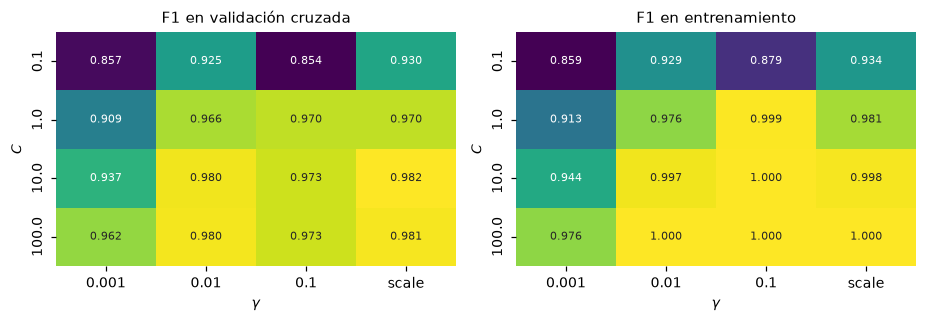

In [8]:
CFG = "global_fruta"
r = pd.read_csv(RESULTADOS / "clasicos_cv" / f"{CFG}_svm.csv")
r["gamma"] = r["param_clf__gamma"].astype(str)
tabla = r.pivot_table(index="param_clf__C", columns="gamma", values="mean_test_score")
tabla_tr = r.pivot_table(index="param_clf__C", columns="gamma", values="mean_train_score")
fig, axes = plt.subplots(1, 2, figsize=(8.5, 3))
for ax, t, titulo in zip(axes, [tabla, tabla_tr], ["F1 en validación cruzada", "F1 en entrenamiento"]):
    sns.heatmap(t, annot=True, fmt=".3f", cmap="viridis", ax=ax, cbar=False, annot_kws={"fontsize": 7})
    ax.set_xlabel("$\\gamma$"); ax.set_ylabel("$C$"); ax.set_title(titulo, fontsize=10)
fig.tight_layout()
guardar_figura(fig, "svm_rejilla")
plt.show()

## 5. Sobreajuste

Se compara el F1 de entrenamiento con el de validación cruzada del mejor modelo de cada tipo, y se trazan curvas de aprendizaje (F1 contra el número de imágenes de entrenamiento).

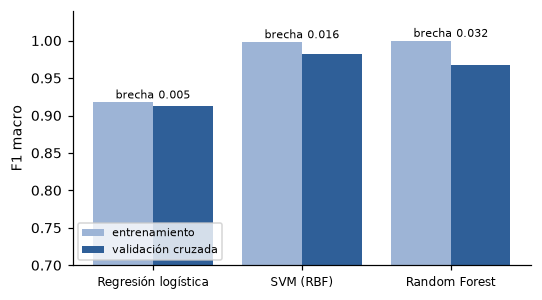

In [9]:
mejor_cfg = cv[cv["configuracion"] == CFG].set_index("modelo")
fig, ax = plt.subplots(figsize=(5, 2.8))
x = np.arange(3)
mods = ["logreg", "svm", "rf"]
ax.bar(x - 0.2, mejor_cfg.loc[mods, "train_f1"], 0.4, label="entrenamiento", color="#9db4d6")
ax.bar(x + 0.2, mejor_cfg.loc[mods, "cv_f1"], 0.4, label="validación cruzada", color="#2f5f98")
for i, m in enumerate(mods):
    ax.text(i, mejor_cfg.loc[m, "train_f1"] + 0.005, f"brecha {mejor_cfg.loc[m, 'train_f1'] - mejor_cfg.loc[m, 'cv_f1']:.3f}",
            ha="center", fontsize=7)
ax.set_xticks(x, [NOMBRES[m] for m in mods], fontsize=8)
ax.set_ylim(0.7, 1.04); ax.set_ylabel("F1 macro"); ax.legend(fontsize=7, loc="lower left")
fig.tight_layout()
guardar_figura(fig, "clasicos_sobreajuste")
plt.show()

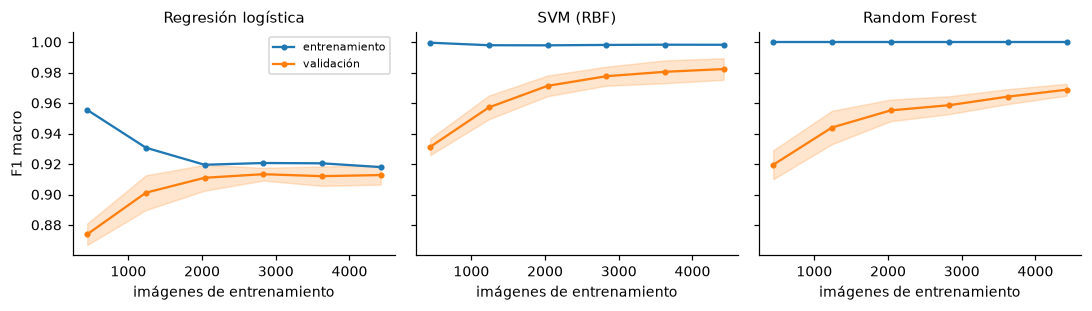

n   train     val  val_std
modelo                                 
logreg 0   442  0.9555  0.8739   0.0070
       1  1238  0.9307  0.9012   0.0114
       2  2034  0.9195  0.9110   0.0085
       3  2830  0.9207  0.9133   0.0042
       4  3626  0.9205  0.9120   0.0064
       5  4423  0.9180  0.9127   0.0063
svm    0   442  0.9995  0.9312   0.0054
       1  1238  0.9979  0.9571   0.0078
       2  2034  0.9978  0.9712   0.0068
       3  2830  0.9981  0.9776   0.0062
       4  3626  0.9982  0.9805   0.0075
       5  4423  0.9982  0.9823   0.0071
rf     0   442  1.0000  0.9195   0.0095
       1  1238  1.0000  0.9439   0.0110
       2  2034  1.0000  0.9551   0.0071
       3  2830  1.0000  0.9586   0.0059
       4  3626  1.0000  0.9642   0.0049
       5  4423  1.0000  0.9687   0.0039

In [10]:
X_dev = matriz(dev, columnas, CFG == "global_fruta")
y_dev = dev["calidad"]
cv5 = StratifiedKFold(5, shuffle=True, random_state=SEMILLA)
fig, axes = plt.subplots(1, 3, figsize=(10, 2.9), sharey=True)
curvas = {}
for ax, m in zip(axes, mods):
    params = json.loads(mejor_cfg.loc[m, "mejores_parametros"])
    modelo = crear_modelo(m).set_params(**{f"clf__{k}": v for k, v in params.items()})
    # hilos en vez de procesos: los procesos de joblib fallan dentro de nbconvert en Windows
    with parallel_backend("threading"):
        tam, tr, va = learning_curve(modelo, X_dev, y_dev, cv=cv5, scoring="f1_macro", n_jobs=-2,
                                     train_sizes=np.linspace(0.1, 1.0, 6), shuffle=True, random_state=SEMILLA)
    curvas[m] = pd.DataFrame({"n": tam, "train": tr.mean(1), "val": va.mean(1), "val_std": va.std(1)})
    ax.plot(tam, tr.mean(1), "o-", label="entrenamiento", ms=3)
    ax.plot(tam, va.mean(1), "o-", label="validación", ms=3)
    ax.fill_between(tam, va.mean(1) - va.std(1), va.mean(1) + va.std(1), alpha=0.2, color="C1")
    ax.set_title(NOMBRES[m], fontsize=10); ax.set_xlabel("imágenes de entrenamiento")
axes[0].set_ylabel("F1 macro"); axes[0].legend(fontsize=7)
fig.tight_layout()
guardar_figura(fig, "clasicos_curvas_aprendizaje")
plt.show()
pd.concat(curvas, names=["modelo"]).round(4).to_csv(RESULTADOS / "clasicos_curvas_aprendizaje.csv")
pd.concat(curvas, names=["modelo"]).round(4)

**Lectura.**
- **Regresión logística:** entrenamiento y validación se juntan rápido y se estancan en 0,91–0,92 desde unas 2.000 imágenes. Es un modelo con **sesgo alto**: más datos no lo mejoran, le falta capacidad.
- **SVM:** F1 de entrenamiento de 0,998 con cualquier cantidad de datos, y la validación sube de 0,93 (442 imágenes) a 0,98 (4.423). La brecha se cierra con más datos, así que la memorización no le impide generalizar dentro del dataset, y todavía gana algo con más imágenes.
- **Random Forest:** F1 de entrenamiento de 1,0 (árboles sin podar) y validación de 0,92 a 0,97; tiene la mayor brecha (0,03) y la curva sigue subiendo.

Ninguno muestra el patrón peligroso de sobreajuste (la validación cae cuando la complejidad aumenta). Lo que sí se ve es que la SVM aprovecha mejor los datos que el Random Forest.

## 6. ¿Qué características usa el modelo?

Dos análisis complementarios:
1. **Por grupo:** F1 de validación cruzada de un Random Forest entrenado con un solo grupo de características.
2. **Individual:** las 15 características más importantes del Random Forest elegido (disminución media de la impureza de Gini).

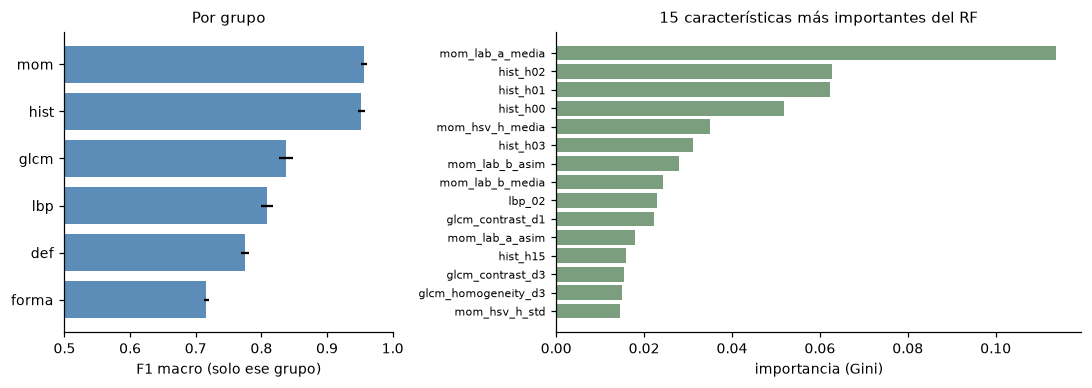

,grupo,n,cv_f1,cv_f1_std
1,mom,18,0.9557,0.0046
0,hist,32,0.9524,0.0050
2,glcm,10,0.8375,0.0102
3,lbp,10,0.8086,0.0089
5,def,3,0.7748,0.0065
4,forma,5,0.7163,0.0038


In [11]:
grupos = columnas_por_grupo(columnas)
filas = []
for g, cols in grupos.items():
    rf = crear_modelo("rf").set_params(clf__n_estimators=200, clf__n_jobs=-2)
    with parallel_backend("threading"):
        s = cross_val_score(rf, dev[cols], y_dev, cv=cv5, scoring="f1_macro")
    filas.append({"grupo": g, "n": len(cols), "cv_f1": s.mean(), "cv_f1_std": s.std()})
por_grupo = pd.DataFrame(filas).sort_values("cv_f1", ascending=False)
por_grupo.round(4).to_csv(RESULTADOS / "clasicos_grupos_caracteristicas.csv", index=False)

rf_final = joblib.load(CHECKPOINTS / f"clasico_{CFG}_rf.joblib")
imp = pd.Series(rf_final.named_steps["clf"].feature_importances_, index=X_dev.columns).sort_values(ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(10, 3.6), gridspec_kw={"width_ratios": [1, 1.6]})
axes[0].barh(por_grupo["grupo"], por_grupo["cv_f1"], xerr=por_grupo["cv_f1_std"], color="#5b8db8")
axes[0].invert_yaxis(); axes[0].set_xlim(0.5, 1); axes[0].set_xlabel("F1 macro (solo ese grupo)")
axes[0].set_title("Por grupo", fontsize=10)
top = imp.head(15)[::-1]
axes[1].barh(top.index, top.values, color="#7a9e7e")
axes[1].tick_params(axis="y", labelsize=7); axes[1].set_xlabel("importancia (Gini)")
axes[1].set_title("15 características más importantes del RF", fontsize=10)
fig.tight_layout()
guardar_figura(fig, "clasicos_importancias")
plt.show()
por_grupo.round(4)

**Lectura.**
- El **color** casi basta: los momentos de color solos llegan a F1 = 0,956 y los histogramas a 0,952. La textura (GLCM 0,84, LBP 0,81), los defectos (0,77) y la forma (0,72) aportan menos por sí solos.
- Las características individuales más importantes son la media de $a^*$ (eje verde–rojo de CIELab) y los primeros cuatro bins del tono ($H < 45$ en la escala 0–180 de OpenCV, es decir 0° a 90°: rojos, cafés, naranjas y amarillos). Coincide con el EDA: las frutas dañadas se desplazan hacia el café.
- Que la forma sirva poco es buena señal: no se está usando el racimo de bananos ni el encuadre como atajo.
- La parte mala: el color medido depende de la luz de la foto, que es justamente una de las condiciones de captura que difieren entre clases. Es otra razón para validar con fotos propias.

## 7. Reconocimiento de la fruta

La configuración con la fruta como variable y los umbrales de tamaño (que son por fruta) necesitan saber qué fruta es. Con las mismas características, un Random Forest la reconoce:

In [12]:
json.loads((RESULTADOS / "clasificador_fruta.json").read_text(encoding="utf8"))

{'n': 966,
 'exactitud': 0.9679,
 'precision_macro': 0.9688,
 'recall_macro': 0.9686,
 'f1_macro': 0.9681,
 'f1_manzana': 0.9545,
 'recall_manzana': 0.924,
 'f1_banano': 0.979,
 'recall_banano': 0.9929,
 'f1_naranja': 0.971,
 'recall_naranja': 0.9887,
 'cv_f1': 0.9704}

## 8. Conclusiones

1. Con características manuales calculadas solo sobre la fruta, la **SVM con kernel RBF** es el mejor modelo clásico: F1 macro de CV 0,982 y de prueba 0,986 [0,977; 0,992], con recall de `mala` de 0,988. El Random Forest queda en 0,970 y la línea base lineal en 0,90.
2. Se elige un **modelo global con la fruta como variable**: rinde igual que un modelo por fruta y es más simple y robusto para la clase `regular`.
3. La SVM memoriza el entrenamiento (0,998), pero su CV y su prueba coinciden y la curva de aprendizaje converge: no hay sobreajuste dañino dentro del dataset.
4. El modelo se apoya sobre todo en el color (tono rojo-café y $a^*$), lo que tiene sentido para detectar fruta dañada pero también es sensible a la iluminación.
5. Las condiciones de captura predicen la calidad con F1 ≈ 0,95 sin mirar la fruta, así que estas cifras son optimistas. La generalización real se mide con las fotos propias en la siguiente fase.